# M2 Validation: SLERP Latent Interpolation
End-to-end M2 validation with A3 latent injection.

In [1]:
from pathlib import Path
import torch
from IPython.display import display
from helpers.methods.access import infer_latent_shape
from helpers.methods.navigation import slerp_latents
from helpers.runtime.inference import generate_prompt_baseline, timed_generate_with_prompt
from helpers.runtime.pipeline import load_flux_pipeline, resolve_runtime_device
from helpers.runtime.utils import flush_namespace, seed_latent
from helpers.runtime.dtype_handler.parsing import resolve_dtype_for_device

WARNING[XFORMERS]: xFormers can't load C++/CUDA extensions. xFormers was built for:
    PyTorch 2.10.0+cu128 with CUDA 1208 (you have 2.11.0+cu130)
    Python  3.10.11 (you have 3.13.11)
  Please reinstall xformers (see https://github.com/facebookresearch/xformers#installing-xformers)
  Memory-efficient attention, SwiGLU, sparse and more won't be available.
  Set XFORMERS_MORE_DETAILS=1 for more details
W0423 19:35:43.418000 48296 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Error occurred while checking dtype torch.float8_e4m3fn on device cuda: "ufunc_add_CUDA" not implemented for 'Float8_e4m3fn'
Candidate FP8 dtype float8_e4m3fn is not supported on device=cuda
Error occurred while checking dtype torch.float8_e5m2 on device cuda: "ufunc_add_CUDA" not implemented for 'Float8_e5m2'
Candidate FP8 dtype float8_e5m2 is not supported on device=cuda
Falling back from FP8 to torch.float16 on device=cuda; tested candidates=[float8_e4m3fn, float8_e5m2]
Enabled layerwise casting on transformer (storage=torch.float16, compute=torch.bfloat16)
Layerwise casting not enabled; skipping fallback attempt


The module 'Flux2Transformer2DModel' is group offloaded and moving it to cuda via `.to()` is not supported.


Enabled group offloading for text_encoder (offload_type=block_level)
Skipping group offload for vae: CUDA error: out of memory
Search for `cudaErrorMemoryAllocation' in https://docs.nvidia.com/cuda/cuda-runtime-api/group__CUDART__TYPES.html for more information.
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.

Loaded pipeline with transformer group offload enabled (use_stream=True, low_cpu_mem_usage=False, enable_text_encoder_group_offload=True, enable_vae_group_offload=True)
Enabled VAE slicing via vae.enable_slicing()
Enabled VAE tiling via vae.enable_tiling()
Skipping channels-last on vae: CUDA error: out of memory
Search for `cudaErrorMemoryAllocation' in https://docs.nvidia.com/cuda/cuda-runtime-api/group__CUDART__TYPES.html for more information.
CUDA kernel errors might be asynchronously r

  0%|          | 0/4 [00:00<?, ?it/s]

baseline in 111.97 s -> C:\Users\David\Desktop\thesis\NeLs\project\python\examples\navigation\outputs\m2_slerp_notebook\m2_baseline.png


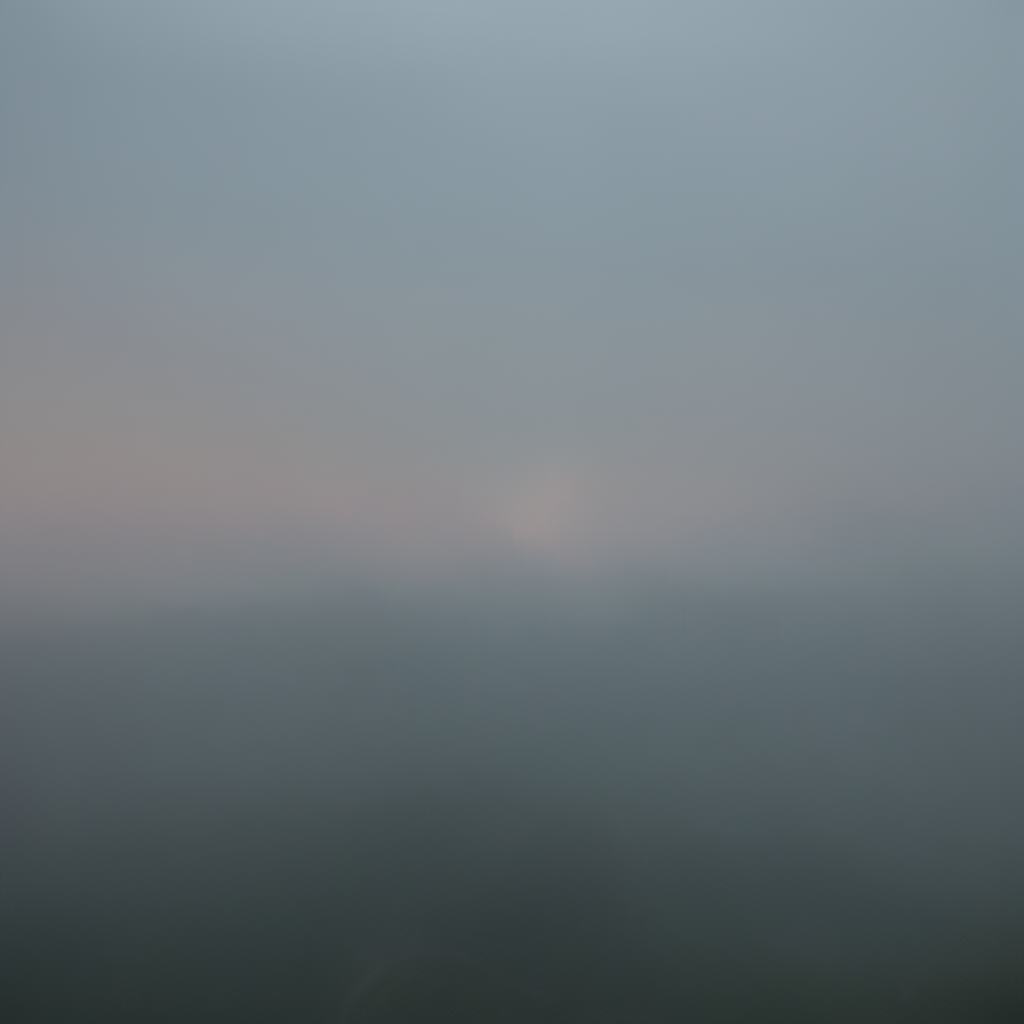

  0%|          | 0/4 [00:00<?, ?it/s]

alpha=0.00 in 406.66 s -> C:\Users\David\Desktop\thesis\NeLs\project\python\examples\navigation\outputs\m2_slerp_notebook\m2_slerp_alpha_0.00.png


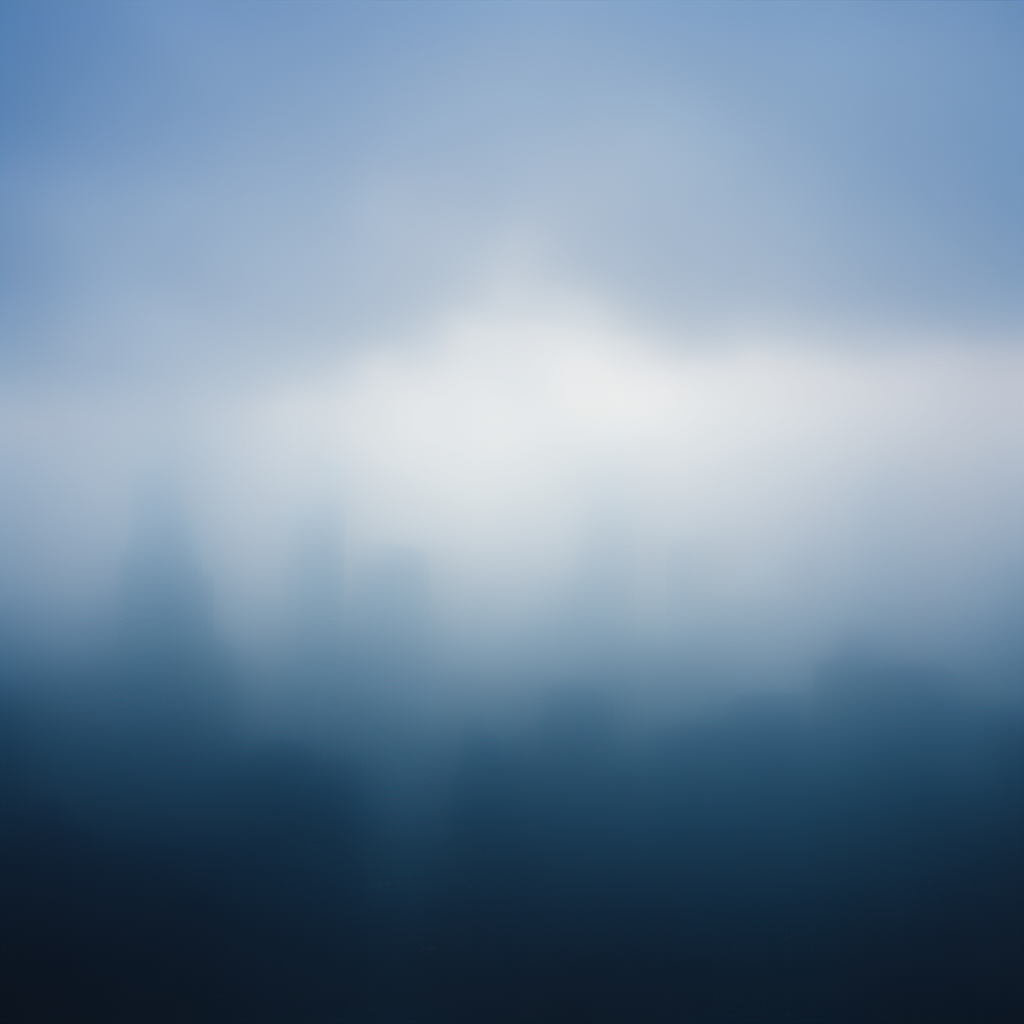

  0%|          | 0/4 [00:00<?, ?it/s]

alpha=0.50 in 431.11 s -> C:\Users\David\Desktop\thesis\NeLs\project\python\examples\navigation\outputs\m2_slerp_notebook\m2_slerp_alpha_0.50.png


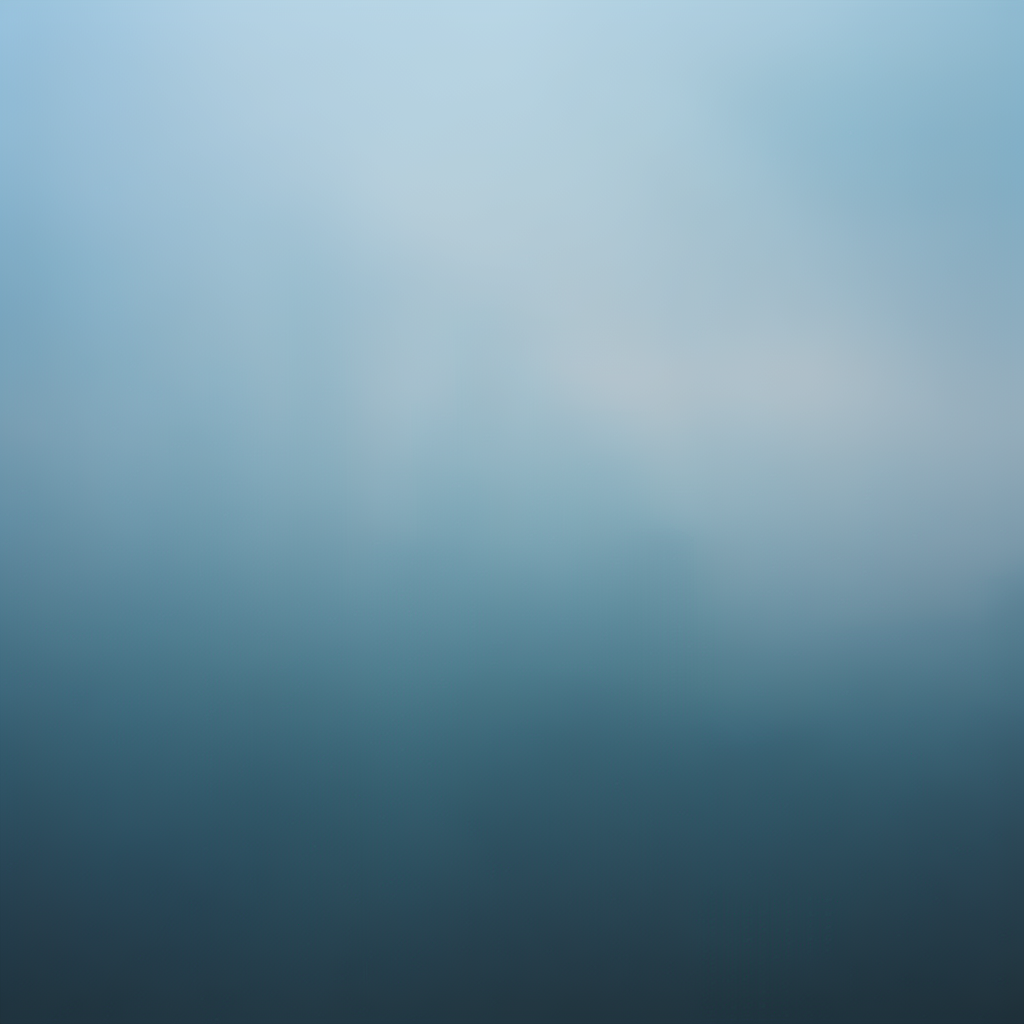

  0%|          | 0/4 [00:00<?, ?it/s]

alpha=1.00 in 433.43 s -> C:\Users\David\Desktop\thesis\NeLs\project\python\examples\navigation\outputs\m2_slerp_notebook\m2_slerp_alpha_1.00.png


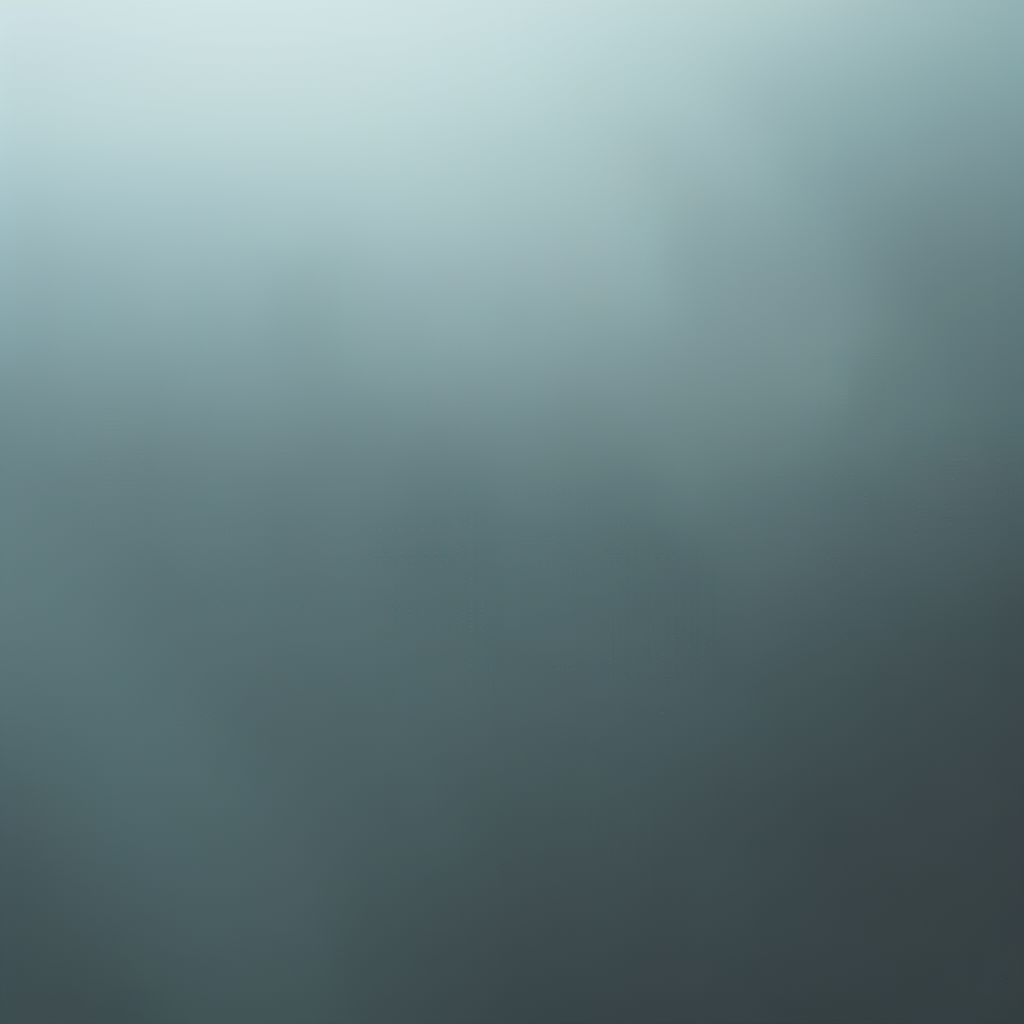

Before flush: allocated=0.17 GB, reserved=8.43 GB, peak_allocated=7.95 GB
After flush: allocated=0.01 GB, reserved=0.02 GB, peak_allocated=0.01 GB


In [ ]:
output_dir = Path("../python/examples/navigation/outputs/m2_slerp_notebook").resolve()
output_dir.mkdir(parents=True, exist_ok=True)

device = resolve_runtime_device()
dtype = resolve_dtype_for_device(device=device)

prompt = "a cinematic city skyline in light fog"
seed = 222
num_inference_steps = 4
guidance_scale = 0.0
try:
    pipe = load_flux_pipeline(
        torch_dtype=dtype,
        device=device,
        offload_mode="none",
        enable_vae_slicing=False,
        enable_vae_tiling=False,
        enable_layerwise_casting=False,
        enable_channels_last=True,
        enable_xformers_attention=True,
        enable_torch_compile=False,
        disable_progress_bar=False
    )

    shape = infer_latent_shape(height=1024, width=1024)
    start = seed_latent(3, shape, dtype)
    end = seed_latent(91, shape, dtype)

    baseline_image, baseline_elapsed, _ = generate_prompt_baseline(
        pipe=pipe,
        prompt=prompt,
        seed=seed,
        num_inference_steps=num_inference_steps,
        guidance_scale=guidance_scale,
        device=device,
    )
    baseline_path = output_dir / "m2_baseline.png"
    baseline_image.save(baseline_path)

    print(f"baseline in {baseline_elapsed:.2f} s -> {baseline_path}")
    display(baseline_image)

    for alpha in [0.0, 0.5, 1.0]:
        latent = slerp_latents(start, end, alpha)

        out, elapsed = timed_generate_with_prompt(
            pipe=pipe,
            prompt=prompt,
            device=device,
            seed=seed,
            latents=latent,
            use_inference_mode=True,
            synchronize_cuda=True,
            num_inference_steps=num_inference_steps,
            guidance_scale=guidance_scale,
        )
        image = out.images[0]

        path = output_dir / f"m2_slerp_alpha_{alpha:.2f}.png"
        image.save(path)

        print(f"alpha={alpha:.2f} in {elapsed:.2f} s -> {path}")
        display(image)
finally:
    flush_namespace(
        globals(),
        "pipe",
        "out",
        "image",
        "latent",
        "start",
        "end",
        "baseline_image",
        verbose=True,
        hard_exit=True
    )